# Week 2: KPI and Sales Analysis
**Objective:** measure overall performance, sales trends, regions and categories, using the cleaned dataset from Week 1.

In [1]:
import os
import pandas as pd
import numpy as np
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

px.defaults.template = "plotly_white"
pd.options.display.float_format = "{:,.2f}".format
os.makedirs("../03_Analysis/charts", exist_ok=True)

## Loading the cleaned data


In [2]:
df = pd.read_csv("../02_Cleaned_Data/superstore_cleaned.csv", parse_dates=["order_date", "ship_date"])
df["postal_code"] = df["postal_code"].astype(str).str.zfill(5)
print(df.shape)

(9993, 29)


## 1. The 7 KPIs

In [3]:
total_sales  = df.sales.sum()
total_profit = df.profit.sum()
total_orders = df.order_id.nunique()
total_cust   = df.customer_id.nunique()
total_qty    = int(df.quantity.sum())
margin       = total_profit / total_sales * 100
aov          = total_sales / total_orders

kpis = pd.DataFrame({
    "KPI": ["Total Sales", "Total Profit", "Total Orders", "Total Customers",
            "Quantity Sold", "Profit Margin (%)", "Average Order Value"],
    "Value": pd.Series([round(total_sales, 2), round(total_profit, 2), total_orders, total_cust,
                        total_qty, round(margin, 2), round(aov, 2)], dtype=object),
    "Formatted": [f"${total_sales:,.2f}", f"${total_profit:,.2f}", f"{total_orders:,}", f"{total_cust:,}",
                  f"{total_qty:,}", f"{margin:.2f}%", f"${aov:,.2f}"],
})
kpis

,KPI,Value,Formatted
0,Total Sales,"2,296,919.49","$2,296,919.49"
1,Total Profit,"286,409.08","$286,409.08"
2,Total Orders,5009,"5,009"
3,Total Customers,793,793
4,Quantity Sold,37871,"37,871"
5,Profit Margin (%),12.47,12.47%
6,Average Order Value,458.56,$458.56


The KPIs shows that over 4 years, the bysiness generated about 2.30 million in sales and 286,409 in profit, a 12.47% profit margin. This came from 5,009 orders placed by 793 customers with 37,871 units sold. The average order is worth $458.56. For every ollar of sales, the business keeps about 12 cents as profit.

## 2. Sales overtime

In [4]:
yearly = df.groupby("year").agg(sales=("sales", "sum"), profit=("profit", "sum"),
                                orders=("order_id", "nunique")).reset_index()
yearly["sales_growth_pct"] = yearly["sales"].pct_change() * 100
yearly["margin_pct"] = yearly["profit"] / yearly["sales"] * 100
yearly

,year,sales,profit,orders,sales_growth_pct,margin_pct
0,2014,"483,966.13","49,556.03",969,NaN,10.24
1,2015,"470,532.51","61,618.60",1038,-2.78,13.10
2,2016,"609,205.60","81,795.17",1315,29.47,13.43
3,2017,"733,215.26","93,439.27",1687,20.36,12.74


## **Yearly findings:**
- Sales fell 2.8% in 2015, then grew 29.5% in 2016 and 20.4% in 2017.
- Orders grew every year, from 969 in 2014 to 1,687 in 2017 (about 74% more), so growth came mainly from more orders.
- Profit rose every year, from $49.6K to $93.4K, even in 2015 when sales fell.
- The profit margin rose from 10.2% (2014) to 13.1% (2015) and 13.4% (2016), then slipped to 12.7% in 2017 even though sales grew by 20%.

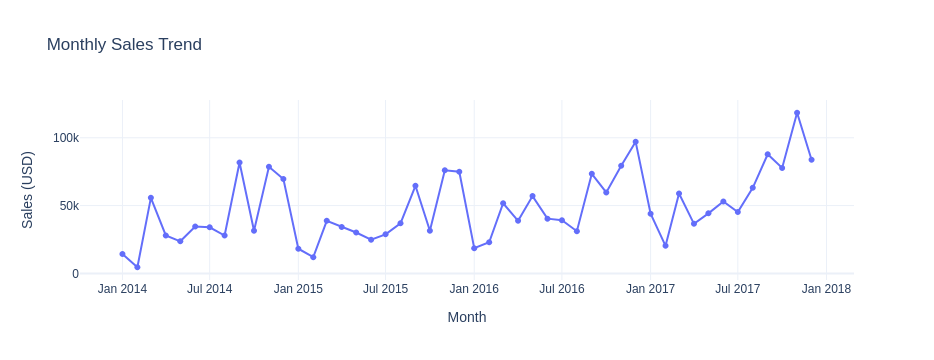

Highest month: 2017-11 118447.82
Lowest month:  2014-02 4519.89


In [5]:
monthly = df.groupby("year_month_sort").agg(sales=("sales", "sum"), profit=("profit", "sum"),
                                            qty=("quantity", "sum")).reset_index()

fig1 = px.line(monthly, x="year_month_sort", y="sales", markers=True, title="Monthly Sales Trend",
               labels={"year_month_sort": "Month", "sales": "Sales (USD)"})
fig1.show()

print("Highest month:", monthly.loc[monthly.sales.idxmax(), "year_month_sort"], round(monthly.sales.max(), 2))
print("Lowest month: ", monthly.loc[monthly.sales.idxmin(), "year_month_sort"], round(monthly.sales.min(), 2))

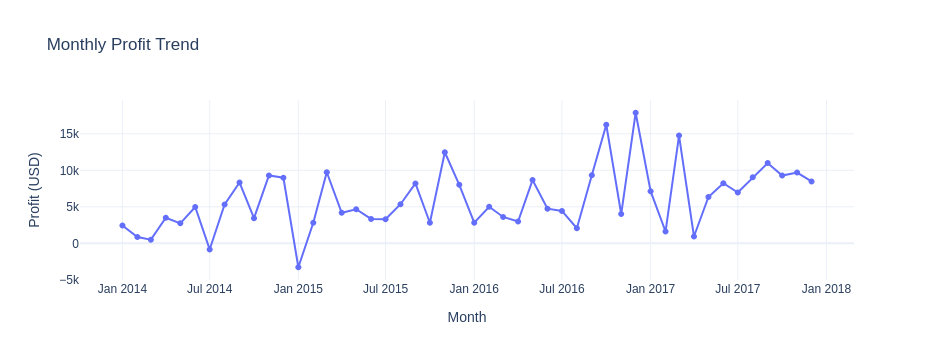

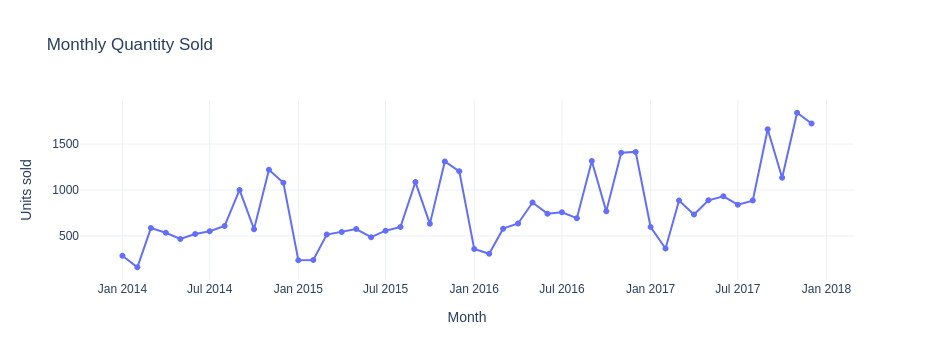

In [6]:
fig_mp = px.line(monthly, x="year_month_sort", y="profit", markers=True, title="Monthly Profit Trend",
                 labels={"year_month_sort": "Month", "profit": "Profit (USD)"})
fig_mp.show()

fig_mq = px.line(monthly, x="year_month_sort", y="qty", markers=True, title="Monthly Quantity Sold",
                 labels={"year_month_sort": "Month", "qty": "Units sold"})
fig_mq.show()

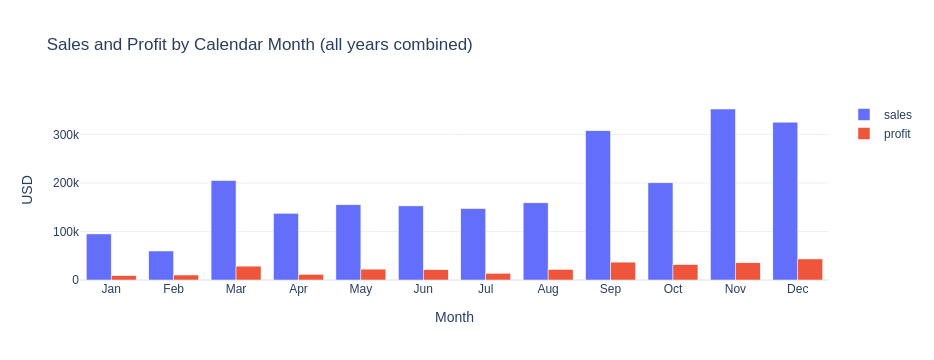

Sep + Nov + Dec share of sales: 42.9 %
Nov + Dec share of sales:       29.5 %
Jan + Feb share of sales:       6.7 %


In [7]:
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
by_month = df.groupby(["month", "month_name"]).agg(sales=("sales", "sum"), profit=("profit", "sum")).reset_index()

fig2 = px.bar(by_month, x="month_name", y=["sales", "profit"], barmode="group",
              category_orders={"month_name": month_order},
              title="Sales and Profit by Calendar Month (all years combined)",
              labels={"month_name": "Month", "value": "USD", "variable": ""})
fig2.show()

share = by_month.set_index("month").sales
print("Sep + Nov + Dec share of sales:", round(share[[9, 11, 12]].sum() / share.sum() * 100, 1), "%")
print("Nov + Dec share of sales:      ", round(share[[11, 12]].sum() / share.sum() * 100, 1), "%")
print("Jan + Feb share of sales:      ", round(share[[1, 2]].sum() / share.sum() * 100, 1), "%")

**Answers to the four questions:**
1. **Highest sales month:** November 2017, with $118,447.82
2. 
3. **Lowest sales month:** February 2014, with $4,519.89
4. **Increasing or decreasing?** Sales are increasing overall. There was a small dip in 2015, followed by strong growth in 2016 and 2017.
5. **Seasonal pattern?** Yes. September, November and December together bring in 42.9% of all sales (November and December alone 29.5%). January and February together bring in only 6.7%. Profit follows the same shape, with December the strongest month and January, February and April among the weakest.

## 3. Regional analysis

,region,sales,profit,orders,margin_pct
0,Central,"501,239.89","39,706.36",1175,7.92
1,East,"678,499.87","91,534.84",1401,13.49
2,South,"391,721.91","46,749.43",822,11.93
3,West,"725,457.82","108,418.45",1611,14.94


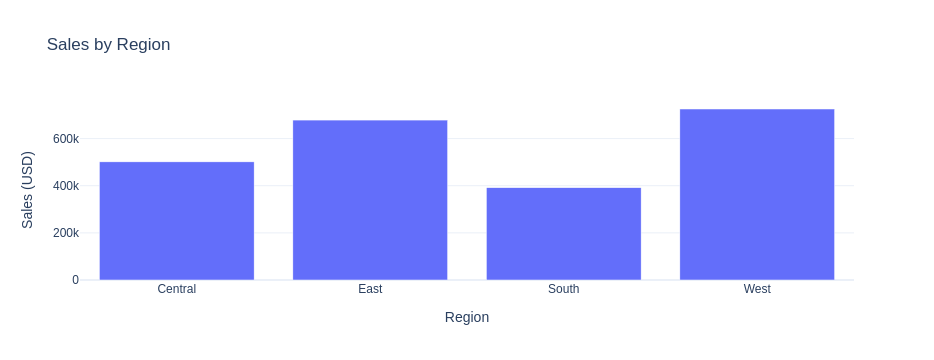

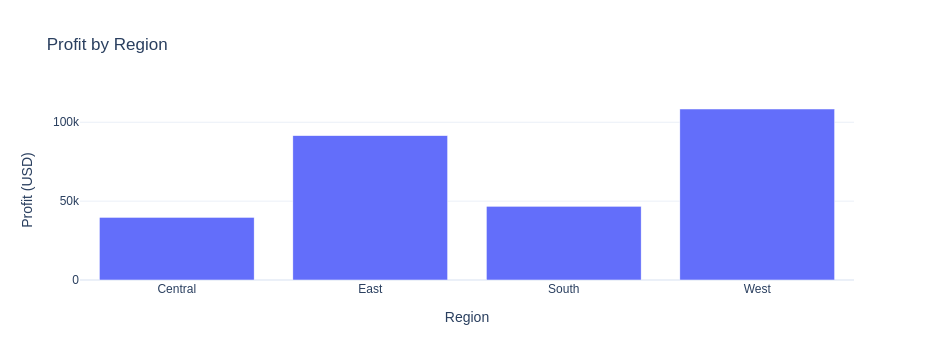

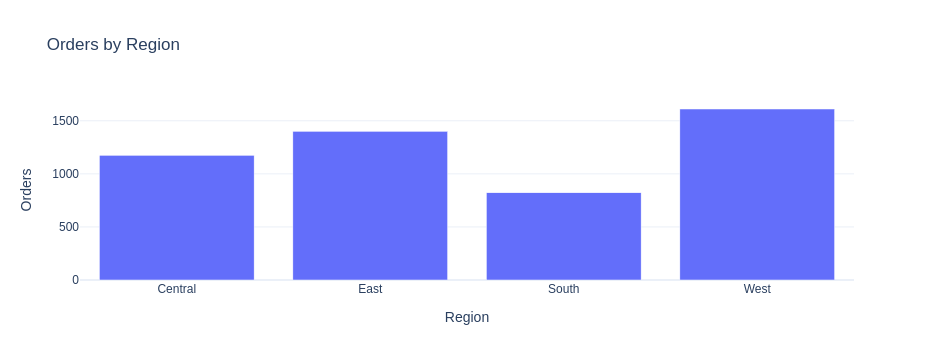

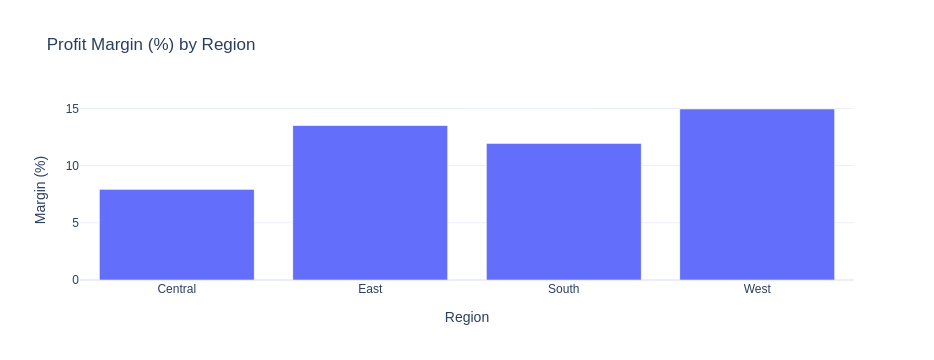

In [8]:
region = df.groupby("region").agg(sales=("sales", "sum"), profit=("profit", "sum"),
                                  orders=("order_id", "nunique")).reset_index()
region["margin_pct"] = region.profit / region.sales * 100
display(region)

fig_rs = px.bar(region, x="region", y="sales", title="Sales by Region", labels={"sales": "Sales (USD)", "region": "Region"})
fig_rp = px.bar(region, x="region", y="profit", title="Profit by Region", labels={"profit": "Profit (USD)", "region": "Region"})
fig_ro = px.bar(region, x="region", y="orders", title="Orders by Region", labels={"orders": "Orders", "region": "Region"})
fig_rm = px.bar(region, x="region", y="margin_pct", title="Profit Margin (%) by Region", labels={"margin_pct": "Margin (%)", "region": "Region"})
for f in (fig_rs, fig_rp, fig_ro, fig_rm):
    f.show()

**Regional findings:**
- **West** generates the most sales ($725K) and the most profit ($108K), and it has the best margin (14.9%). So here the highest-sales region is also the most profitable one.
- **East** is second on both measures (sales $678K, profit $92K, margin 13.5%).
- **Central** sells more than South ($501K against $392K) but earns less profit ($39.7K against $46.7K). Its margin of 7.9% is the weakest, so Central is the region that needs attention.
- **South** has the fewest orders (822) and the lowest sales, but a healthy margin of 11.9%.

## 4. Category analysis

,category,sales,profit,qty,margin_pct,sales_share_pct,profit_share_pct
0,Furniture,"741,718.42","18,463.33",8026,2.49,32.29,6.45
1,Office Supplies,"719,047.03","122,490.80",22906,17.04,31.30,42.77
2,Technology,"836,154.03","145,454.95",6939,17.40,36.40,50.79


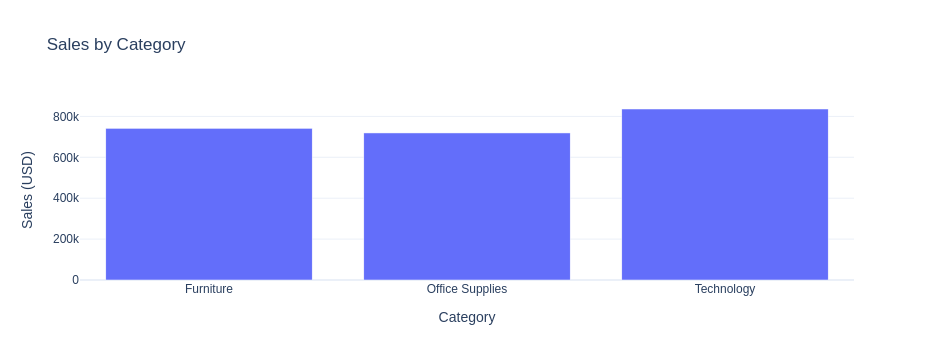

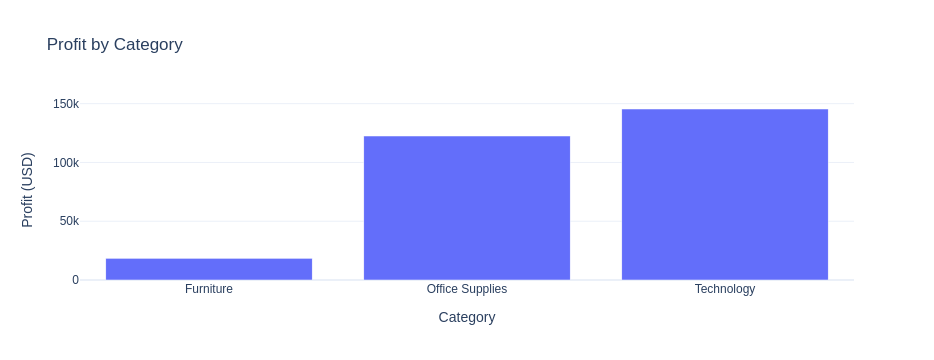

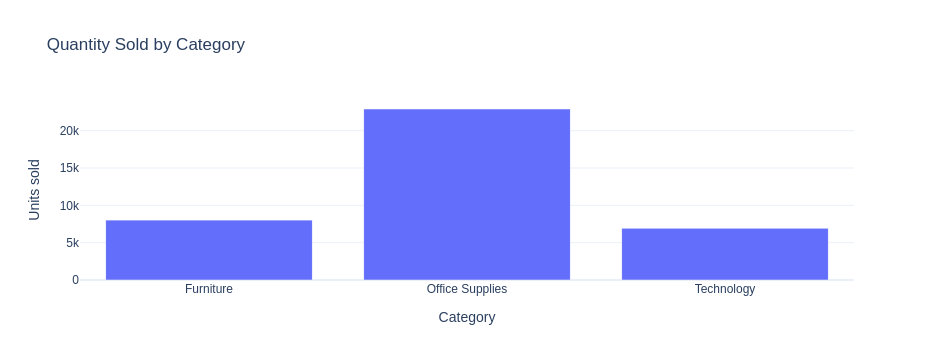

In [9]:
cat = df.groupby("category").agg(sales=("sales", "sum"), profit=("profit", "sum"),
                                 qty=("quantity", "sum")).reset_index()
cat["margin_pct"] = cat.profit / cat.sales * 100
cat["sales_share_pct"] = cat.sales / cat.sales.sum() * 100
cat["profit_share_pct"] = cat.profit / cat.profit.sum() * 100
display(cat)

fig_cs = px.bar(cat, x="category", y="sales", title="Sales by Category", labels={"sales": "Sales (USD)", "category": "Category"})
fig_cp = px.bar(cat, x="category", y="profit", title="Profit by Category", labels={"profit": "Profit (USD)", "category": "Category"})
fig_cq = px.bar(cat, x="category", y="qty", title="Quantity Sold by Category", labels={"qty": "Units sold", "category": "Category"})
for f in (fig_cs, fig_cp, fig_cq):
    f.show()

**Category findings:**
- **Technology** has the highest sales ($836K, 36.4% of sales) and the highest profit ($145K, 50.8% of all profit), with a 17.4% margin, while selling the fewest units (6,939).
- **Office Supplies** sells by far the most units (22,906), earns a 17.0% margin, and contributes 42.8% of profit.
- **Furniture** accounts for 32.3% of sales but only 6.4% of profit, with a margin of just 2.5%. It sells nearly as much as the other categories but keeps almost nothing, so it needs a pricing and discount review.

## 5. Basic EDA

,sales,quantity,discount,profit
count,"9,993.00","9,993.00","9,993.00","9,993.00"
mean,229.85,3.79,0.16,28.66
std,623.28,2.23,0.21,234.27
min,0.44,1.00,0.00,"-6,599.98"
25%,17.28,2.00,0.00,1.73
50%,54.48,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,"22,638.48",14.00,0.80,"8,399.98"


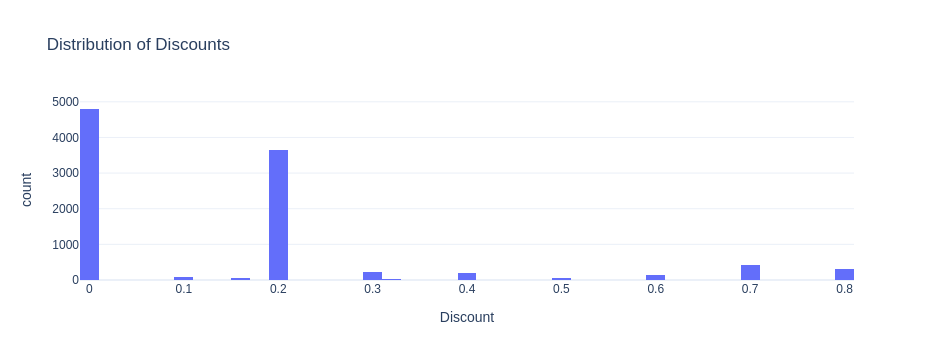

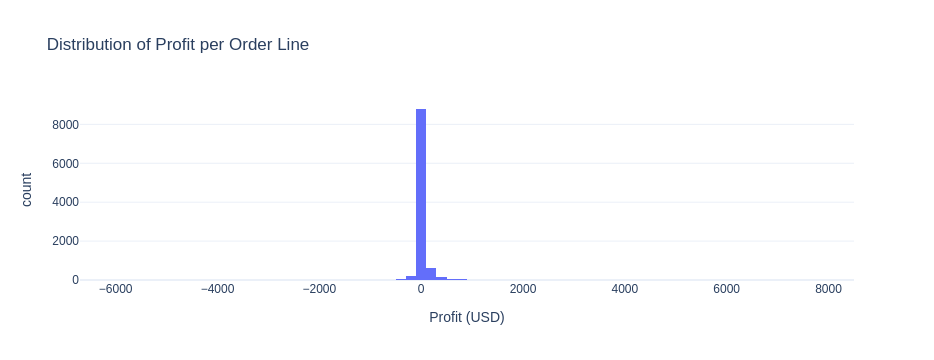

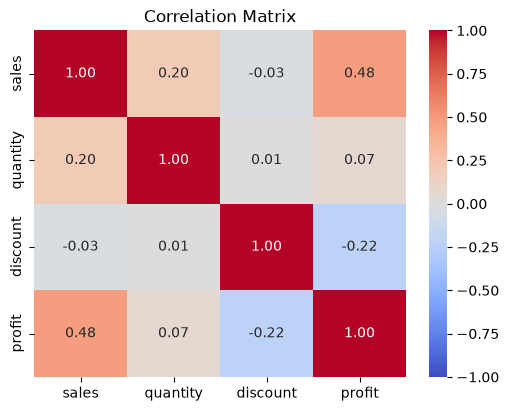

Loss-making order lines: 1870 (18.7% of all lines)
Total of those losses:  -156119.23


In [10]:
display(df[["sales", "quantity", "discount", "profit"]].describe())

fig_hd = px.histogram(df, x="discount", title="Distribution of Discounts", labels={"discount": "Discount"})
fig_hp = px.histogram(df, x="profit", nbins=80, title="Distribution of Profit per Order Line", labels={"profit": "Profit (USD)"})
fig_hd.show()
fig_hp.show()

plt.figure(figsize=(6, 4.5))
sns.heatmap(df[["sales", "quantity", "discount", "profit"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.savefig("../03_Analysis/charts/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

print("Loss-making order lines:", int(df.is_loss.sum()), f"({df.is_loss.mean() * 100:.1f}% of all lines)")
print("Total of those losses: ", round(df.loc[df.is_loss, "profit"].sum(), 2))

**EDA findings:**
- **Sales are heavily skewed.** The average order line is $229.85 but the median is only $54.48, and the largest is $22,638. A few big orders pull the average up.
- **Discounts** range from 0% to 80%. The median is 20%, and many lines have no discount at all.
- **Profit** is also skewed: the median line earns $8.67, but losses reach -$6,600 and gains reach +$8,400.
- **18.7% of order lines (1,870) lose money**, totalling about -$156K.
- **Correlations:** discount and profit have a negative relationship (-0.22). Discount and sales have almost none (-0.03), so higher discounts do not appear to lift the sales value of a line. Sales and profit are positively related (0.48). Correlation is not proof of cause, so discounts are examined properly in Week 4.

## 6. Business insights
Each insight states what the data shows, why it matters and what management could do.

1. **Growth is strong and driven by order volume.** Sales grew 29.5% in 2016 and 20.4% in 2017 after a 2.8% dip in 2015, and orders rose from 969 to 1,687 over four years. *Action:* protect the customer-acquisition activity that is driving this growth.
2. **Sales are highly seasonal.** September, November and December bring in 42.9% of annual sales, while January and February bring only 6.7%. *Action:* plan stock and staffing ahead of the autumn peak, and run targeted promotions in the weak early months.
3. **Furniture sells a lot but earns almost nothing.** It makes 32.3% of sales but only 6.4% of profit (2.5% margin). *Action:* review Furniture pricing, supplier costs and discounting.
4. **Technology and Office Supplies carry the business.** Together they provide 93.6% of profit. *Action:* prioritise stock availability and marketing for these two categories.
5. **Central region is the weak spot.** It out-sells South but earns less profit, with a margin of 7.9% against 14.9% in the West. *Action:* investigate why Central margins are low (discounting, product mix, shipping costs).
6. **Heavy discounting is linked to losses.** Lines with discounts above 20% (1,392 lines) lost about $135K in total, while undiscounted lines earned about $321K, and the discount-profit correlation is negative (-0.22). *Action:* set a discount cap and examine this in depth in Week 4.
7. **Growth in 2017 was less profitable.** Sales rose 20.4% but the margin slipped from 13.4% to 12.7%. *Action:* monitor margin alongside sales, so that growth does not come from unprofitable sales.

## Saving charts and the results

In [11]:
figs = {
    "monthly_sales": fig1, "monthly_profit": fig_mp, "monthly_quantity": fig_mq,
    "calendar_month_sales_profit": fig2,
    "sales_by_region": fig_rs, "profit_by_region": fig_rp, "orders_by_region": fig_ro, "margin_by_region": fig_rm,
    "sales_by_category": fig_cs, "profit_by_category": fig_cp, "quantity_by_category": fig_cq,
    "discount_distribution": fig_hd, "profit_distribution": fig_hp,
}
for name, f in figs.items():
    f.write_html(f"../03_Analysis/charts/{name}.html", include_plotlyjs="cdn")

with pd.ExcelWriter("../03_Analysis/analysis.xlsx") as writer:
    kpis.to_excel(writer, sheet_name="KPIs", index=False)
    yearly.to_excel(writer, sheet_name="Yearly", index=False)
    monthly.to_excel(writer, sheet_name="Monthly", index=False)
    by_month.to_excel(writer, sheet_name="CalendarMonth", index=False)
    region.to_excel(writer, sheet_name="Region", index=False)
    cat.to_excel(writer, sheet_name="Category", index=False)

print(len(os.listdir("../03_Analysis/charts")), "chart files saved")
print(pd.ExcelFile("../03_Analysis/analysis.xlsx").sheet_names)

15 chart files saved
['KPIs', 'Yearly', 'Monthly', 'CalendarMonth', 'Region', 'Category']
